In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
# -------------------------------------------------------------------
# 1. Load and Preprocess Dataset
# -------------------------------------------------------------------
# Load MNIST dataset (60k train images, 10k test images of shape 28x28)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values from [0, 255] to [0.0, 1.0]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape data to include the channel dimension: (Batch, Height, Width, Channels)
# Grayscale images have 1 channel (28, 28, 1)
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape:     {X_test.shape}")

Training data shape: (60000, 28, 28, 1)
Test data shape:     (10000, 28, 28, 1)


In [4]:
# -------------------------------------------------------------------
# 2. Build 2D CNN Architecture
# -------------------------------------------------------------------
model = models.Sequential([
    # Input Layer explicitly defining shape (28x28 grayscale)
    layers.Input(shape=(28, 28, 1)),

    # 1st Convolutional Block
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # 2nd Convolutional Block
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten output maps into a 1D vector for Dense layers
    layers.Flatten(),
    
    # Fully-Connected Dense Layers with Dropout for Regularization
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    
    # Output Layer: 10 units for digits 0-9 with Softmax probabilities
    layers.Dense(10, activation='softmax')
])

# Print summary of network parameters and layers
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# -------------------------------------------------------------------
# 3. Compile the Model
# -------------------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # Accepts integer target labels (0-9)
    metrics=['accuracy']
)

In [6]:
# -------------------------------------------------------------------
# 4. Train the Model with Early Stopping
# -------------------------------------------------------------------
BATCH_SIZE = 64
EPOCHS = 50  # Maximum cap; early stopping will halt training sooner if needed

# Configure Early Stopping Callback
early_stopping = EarlyStopping(
    monitor='val_accuracy',      # Metric to monitor
    mode='max',                  # We want to maximize validation accuracy
    patience=3,                  # Number of epochs to wait for improvement before stopping
    restore_best_weights=True,   # Automatically keep weights from the epoch with best accuracy
    verbose=1                    # Print message when early stopping triggers
)

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,        # Uses 10% of training set for validation each epoch
    callbacks=[early_stopping],  # Pass the callback list here
    verbose=1
)

Epoch 1/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9276 - loss: 0.2324 - val_accuracy: 0.9852 - val_loss: 0.0544
Epoch 2/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9759 - loss: 0.0780 - val_accuracy: 0.9878 - val_loss: 0.0433
Epoch 3/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9813 - loss: 0.0590 - val_accuracy: 0.9905 - val_loss: 0.0380
Epoch 4/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9842 - loss: 0.0506 - val_accuracy: 0.9887 - val_loss: 0.0391
Epoch 5/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9863 - loss: 0.0425 - val_accuracy: 0.9900 - val_loss: 0.0366
Epoch 6/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9873 - loss: 0.0373 - val_accuracy: 0.9907 - val_loss: 0.0354
Epoch 7/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9888 - loss: 0.0342 - val_accuracy: 0.9907 - val_loss: 0.0318
Epoch 8/50
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9896 - loss: 0.0306 - va

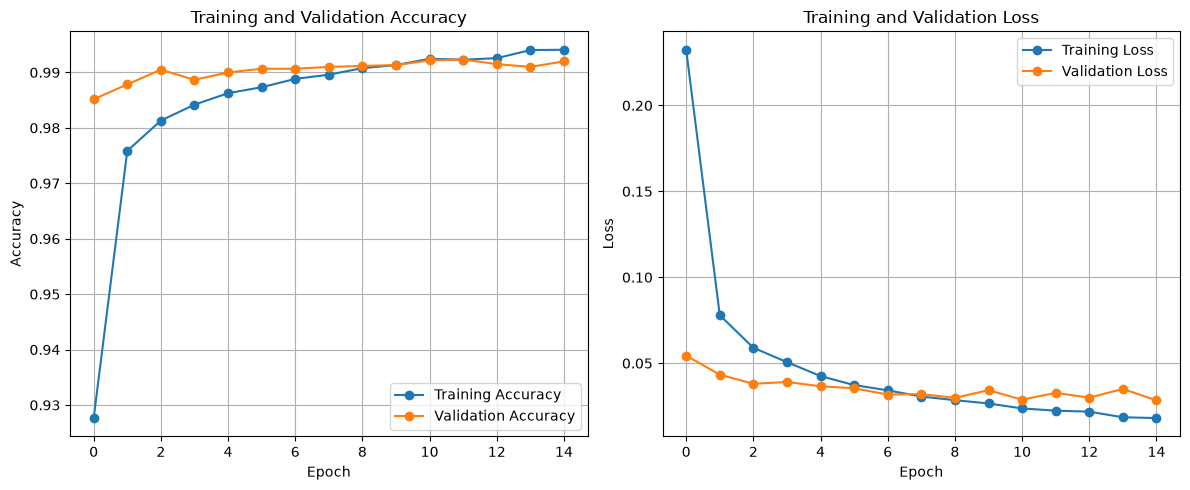

In [7]:
# -------------------------------------------------------------------
# Plot Training & Validation Accuracy and Loss Curves
# -------------------------------------------------------------------
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# 1. Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

# 2. Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
# -------------------------------------------------------------------
# 5. Evaluate on Test Dataset
# -------------------------------------------------------------------
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\n---> Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"---> Test Loss:     {test_loss:.4f}")


---> Test Accuracy: 99.20%
---> Test Loss:     0.0235


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


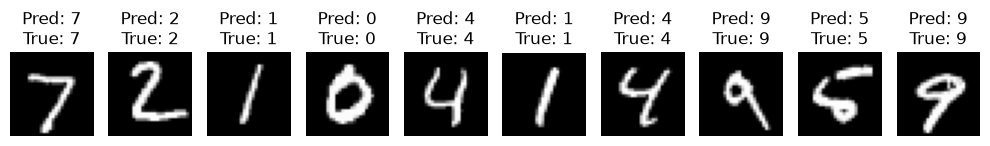

In [10]:
# -------------------------------------------------------------------
# 6. Make Predictions & Visualize Results
# -------------------------------------------------------------------
n=10
predictions = model.predict(X_test[:n])

fig, axes = plt.subplots(1, n, figsize=(10, 3))
for i in range(n):
    axes[i].imshow(X_test[i].squeeze(), cmap='gray')
    pred_label = np.argmax(predictions[i])
    true_label = y_test[i]
    axes[i].set_title(f"Pred: {pred_label}\nTrue: {true_label}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [17]:
# -------------------------------------------------------------------
# 7. Save Model
# -------------------------------------------------------------------
model.save("Modelo.keras")
print("\nModel saved successfully as 'Modelo.keras'")


Model saved successfully as 'Modelo.keras'
